# Modul 03: Formal Hypothesis Testing, Predictive Modeling & Cost-Sensitive Optimization
### Mata Kuliah: Data Mining — Program Studi Teknik Informatika
**Dosen Pengampu:** Abu Salam, M.Kom  
**Penyusun:** Nayyara Rauf Ghani Al Khayri (NIM: A11.2024.16055)  
**Lingkungan Eksekusi:** Local Python 3.13 Virtual Environment (`.venv`) + SQLite Database  

---

## 1. Executive Summary & Problem Framing

### 1.1 Konteks Bisnis & Metodologi Pemodelan
Tujuan akhir dari *Data Mining Pipeline* ini adalah mentransformasikan hipotesis bisnis menjadi bukti empiris yang teruji secara statistik, serta membangun model prediktif *machine learning* yang tidak hanya akurat secara matematis, namun juga mengoptimalkan nilai ekonomis perusahaan.

Dalam kasus retensi pelanggan telekomunikasi (*Telco Churn*):
1. **Asimetri Biaya Keputusan (*Asymmetric Misclassification Cost*)**:
   - **False Negative (FN)**: Model memprediksi pelanggan akan bertahan (*Stay*), namun pada kenyataannya pelanggan melakukan *Churn*. Perusahaan kehilangan seluruh nilai masa hidup pelanggan (*Customer Lifetime Value* / LTV) dengan estimasi kerugian $C_{FN} = \$500$.
   - **False Positive (FP)**: Model memprediksi pelanggan akan *Churn*, namun pada kenyataannya pelanggan berniat loyal (*Stay*). Perusahaan mengeluarkan biaya intervensi promosi diskon yang sebenarnya tidak diperlukan, dengan biaya $C_{FP} = \$50$.
   - Menggunakan ambang batas probabilitas standar ($\tau = 0.50$) pada dataset yang tidak seimbang sering kali menghasilkan penalti finansial yang besar karena membiarkan terlalu banyak *False Negatives*.

Tujuan utama dari **Modul 03** adalah:
1. **Formal Hypothesis Testing**: Menguji korelasi antar variabel secara inferensial menggunakan **Pearson's Chi-Square Test of Independence** (dengan *Cramer's V*), **One-Way ANOVA** (dengan *Eta-Squared*), **Welch's Independent T-Test** (dengan *Cohen's d*), dan mitigasi kesalahan Tipe I melalui **Koreksi Bonferroni**.
2. **Stratified K-Fold Cross Validation**: Mencegah kebocoran data (*data leakage*) dan bias distribusi dengan partisi terskema 5-Fold Stratified CV.
3. **Hyperparameter Tuning & Multi-Architecture Benchmark**: Membandingkan model dasar (*Baseline* Logistic Regression), *Tree Ensemble* (Random Forest), *State-of-the-Art Gradient Boosting* (XGBoost), dan *Voting Ensemble*.
4. **Dual Metric Evaluation (ROC-AUC & PR-AUC)**: Menganalisis trade-off performa melalui kurva ROC (*Receiver Operating Characteristic*) dan kurva PR (*Precision-Recall*), yang esensial untuk kelas target tak seimbang (*class imbalance*).
5. **Cost-Sensitive Threshold Optimization ($\tau^*$)**: Menemukan ambang batas probabilitas optimal yang meminimalkan total kerugian finansial perusahaan.
6. **Persistence & Strategic Action Plan**: Menyimpan metrik evaluasi ke tabel SQLite `model_metrics` dan merumuskan rekomendasi retensi berbasis data.


## 2. Pipeline Architecture & Workflow

Diagram alir inferensi statistik dan pemodelan prediktif Modul 03:

```
+---------------------------------------------------------------------------------+
|               MODUL 03: HYPOTHESIS TESTING & PREDICTIVE MODELING                |
+---------------------------------------------------------------------------------+
                                         |
                                         v
                      [SQLite: Query featured_customers]
                                         |
                                         v
                       [Formal Hypothesis Testing Suite]
                         - Chi-Square Test of Independence (Cramer's V)
                         - One-Way ANOVA (Eta-Squared)
                         - Welch's Two-Sample T-Test (Cohen's d)
                         - Bonferroni FWER Multiple-Testing Correction
                                         |
                                         v
                       [Stratified 5-Fold Cross Validation]
                                         |
                                         v
                    [Hyperparameter Tuning (GridSearchCV)]
                         - Logistic Regression (L2 Regularization)
                         - Random Forest (Depth & Split Optimization)
                         - XGBoost Classifier (scale_pos_weight & Subsample)
                         - Soft-Voting Ensemble (RF + XGBoost)
                                         |
                                         v
                     [Comprehensive Performance Benchmark]
                         - ROC-AUC & Precision-Recall (PR-AUC)
                         - Confusion Matrix & Classification Report
                                         |
                                         v
                    [Cost-Sensitive Threshold Optimization]
                         - Total Cost = (FN * $500) + (FP * $50)
                         - Optimal Decision Boundary Threshold tau*
                                         |
                                         v
                       [SQLite: Persist model_metrics]
                                         &
                         [Executive Action Retention Plan]
```


In [1]:
# Setup Lingkungan Kerja & Import Modul Modular
import sys
from pathlib import Path

ROOT_DIR = Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    DB_PATH, FEATURED_TABLE, METRICS_TABLE, TARGET_COLUMN,
    COST_FALSE_NEGATIVE, COST_FALSE_POSITIVE, RANDOM_STATE
)
from src.logger import get_logger
from src.database import read_from_sqlite, log_model_metric
from src.hypothesis_testing import (
    perform_chi_square_test, perform_one_way_anova,
    perform_independent_ttest, apply_bonferroni_correction
)
from src.modeling import (
    prepare_modeling_data, build_and_tune_models,
    evaluate_models_on_test, optimize_decision_threshold,
    plot_combined_roc_and_pr_curves, plot_cost_threshold_curve,
    plot_confusion_matrices, plot_feature_importance_top
)

logger = get_logger("Notebook_03")
logger.info("Modul 03: Environment siap digunakan.")


2026-10-24 23:47:43 | INFO     | Notebook_03:<module>:32 - Modul 03: Environment siap digunakan.


---

## 3. Ekstraksi Dataset Siap Latih dari SQLite Feature Store

Kita memuat dataset berfitur lengkap yang telah di-encode dan ditransformasikan dari tabel `featured_customers`.


In [2]:
# Membaca data dari tabel featured_customers di SQLite
df_featured = read_from_sqlite(FEATURED_TABLE, db_path=DB_PATH)

print(f"Dataset berhasil dimuat dari SQLite '{FEATURED_TABLE}'.")
print(f"Dimensi Data: {df_featured.shape[0]} observasi x {df_featured.shape[1]} kolom.")
display(df_featured.head(3))


2026-10-24 23:47:43 | INFO     | DatabaseManager:read_from_sqlite:133 - Executing SQLite query: SELECT * FROM featured_customers...


2026-10-24 23:47:43 | INFO     | DatabaseManager:read_from_sqlite:136 - Query returned 1200 rows and 27 columns.


Dataset berhasil dimuat dari SQLite 'featured_customers'.
Dimensi Data: 1200 observasi x 27 kolom.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,Contract,PaperlessBilling,MonthlyCharges,...,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,TechSupport_No internet service,TechSupport_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1001-ABCD,1,0,0,0,43.0,1,0,0,75.01,...,0,1,0,0,0,1,0,1,0,0
1,1002-ABCD,0,0,0,0,72.0,1,0,0,59.50,...,0,1,0,1,0,1,0,0,1,0
2,1003-ABCD,1,0,1,1,72.0,1,0,0,65.23,...,0,1,0,0,1,1,0,0,0,1


---

## 4. Formal Statistical Hypothesis Testing & Inferensi Bisnis

Sebelum memodelkan algoritma pembelajaran mesin, kita wajib menguji hipotesis statistik formal untuk membuktikan secara inferensial apakah relasi antar variabel merupakan fenomena acak (*sampling noise*) atau benar-benar kausalitas statistik yang signifikan.


In [3]:
# Uji 1: Pearson's Chi-Square Test of Independence (Contract vs Churn)
# Kita gunakan df_clean untuk mempertahankan nama label asli dalam pengujian
from src.config import CLEANED_TABLE
df_clean = read_from_sqlite(CLEANED_TABLE, db_path=DB_PATH)

chi_result = perform_chi_square_test(df_clean, col_x="Contract", col_y="Churn", alpha=0.05)
print("=== [UJI 1] HASIL CHI-SQUARE TEST OF INDEPENDENCE ===")
print(f"Chi-Square Statistic: {chi_result['chi2_statistic']}")
print(f"Degrees of Freedom  : {chi_result['degrees_of_freedom']}")
print(f"p-value             : {chi_result['p_value']:.4e}")
print(f"Cramer's V          : {chi_result['cramers_v']} ({chi_result['effect_strength']})")
print(f"Keputusan Uji       : {'TOLAK H0' if chi_result['reject_null'] else 'GAGAL TOLAK H0'}")
print(f"\nTabel Kontingensi:\n{chi_result['contingency_table']}")
print(f"\nInterpretasi Bisnis:\n{chi_result['business_interpretation']}")

# Uji 2: One-Way ANOVA (MonthlyCharges across Contract Groups)
anova_result = perform_one_way_anova(df_clean, group_col="Contract", value_col="MonthlyCharges", alpha=0.05)
print("\n=== [UJI 2] HASIL ONE-WAY ANOVA ===")
print(f"F-Statistic         : {anova_result['f_statistic']}")
print(f"p-value             : {anova_result['p_value']:.4e}")
print(f"Eta-Squared (eta^2) : {anova_result['eta_squared']} ({anova_result['effect_strength']})")
print(f"Keputusan Uji       : {'TOLAK H0' if anova_result['reject_null'] else 'GAGAL TOLAK H0'}")
print(f"\nStatistik Kelompok:\n{pd.DataFrame(anova_result['group_statistics'])}")
print(f"\nInterpretasi Bisnis:\n{anova_result['business_interpretation']}")

# Uji 3: Welch's Two-Sample Independent T-Test (tenure across Churn Groups)
ttest_result = perform_independent_ttest(df_clean, group_col="Churn", value_col="tenure", alpha=0.05)
print("\n=== [UJI 3] HASIL WELCH'S INDEPENDENT T-TEST ===")
print(f"T-Statistic         : {ttest_result['t_statistic']}")
print(f"p-value             : {ttest_result['p_value']:.4e}")
print(f"Cohen's d           : {ttest_result['cohens_d']}")
print(f"Keputusan Uji       : {'TOLAK H0' if ttest_result['reject_null'] else 'GAGAL TOLAK H0'}")
print(f"\nInterpretasi Bisnis:\n{ttest_result['business_interpretation']}")

# Mitigasi Kesalahan Tipe I: Koreksi Bonferroni
p_vals = [chi_result["p_value"], anova_result["p_value"], ttest_result["p_value"]]
bonferroni_summary = apply_bonferroni_correction(p_vals, family_alpha=0.05)
print("\n=== KOREKSI BONFERRONI (FAMILY-WISE ERROR RATE CONTROL) ===")
print(f"Ambang Batas Alpha Terkoreksi: {bonferroni_summary['bonferroni_alpha_threshold']:.5f}")
print(f"Jumlah Hipotesis Signifikan  : {bonferroni_summary['total_significant_discoveries']} dari {bonferroni_summary['number_of_tests']}")


2026-10-24 23:47:43 | INFO     | DatabaseManager:read_from_sqlite:133 - Executing SQLite query: SELECT * FROM cleaned_customers...


2026-10-24 23:47:43 | INFO     | DatabaseManager:read_from_sqlite:136 - Query returned 1200 rows and 18 columns.


2026-10-24 23:47:43 | INFO     | HypothesisTesting:perform_chi_square_test:42 - Conducting Chi-Square Test: 'Contract' vs 'Churn' (alpha=0.05)...


2026-10-24 23:47:43 | INFO     | HypothesisTesting:perform_chi_square_test:86 - Chi-Square Result: chi2=143.88, p_val=5.71e-32, Cramer's V=0.3463, Reject H0=True


=== [UJI 1] HASIL CHI-SQUARE TEST OF INDEPENDENCE ===
Chi-Square Statistic: 143.8814
Degrees of Freedom  : 2
p-value             : 5.7090e-32
Cramer's V          : 0.3463 (Strong)
Keputusan Uji       : TOLAK H0

Tabel Kontingensi:
Churn            No  Yes
Contract                
Month-to-month  268  398
One year        171   96
Two year        218   49

Interpretasi Bisnis:
Dengan p-value = 5.7090e-32 (< alpha 0.05), terdapat bukti statistik yang sangat kuat untuk MENOLAK hipotesis nol (H0). Karakteristik 'Contract' memiliki korelasi yang signifikan secara statistik terhadap 'Churn' dengan tingkat kekuatan asosiasi Strong (Cramer's V = 0.3463). Bagi manajemen, hal ini membuktikan bahwa segmentasi berdasarkan 'Contract' harus dijadikan pilar utama strategi retensi.
2026-10-24 23:47:43 | INFO     | HypothesisTesting:perform_one_way_anova:116 - Conducting One-Way ANOVA: 'MonthlyCharges' across 'Contract' groups...


2026-10-24 23:47:43 | INFO     | HypothesisTesting:perform_one_way_anova:160 - ANOVA Result: F=0.07, p_val=9.30e-01, eta^2=0.0001, Reject H0=False



=== [UJI 2] HASIL ONE-WAY ANOVA ===
F-Statistic         : 0.073
p-value             : 9.2959e-01
Eta-Squared (eta^2) : 0.0001 (Small Effect)
Keputusan Uji       : GAGAL TOLAK H0

Statistik Kelompok:
       Month-to-month  One year  Two year
count          666.00    267.00    267.00
mean            63.12     62.59     62.89
std             19.33     19.70     19.64

Interpretasi Bisnis:
Dengan p-value = 0.9296 (>= alpha 0.05), GAGAL menolak H0. Rata-rata 'MonthlyCharges' tidak berbeda nyata antar grup.

=== [UJI 3] HASIL WELCH'S INDEPENDENT T-TEST ===
T-Statistic         : -2.5629
p-value             : 1.0510e-02
Cohen's d           : -0.1498
Keputusan Uji       : TOLAK H0

Interpretasi Bisnis:
Perbedaan rata-rata 'tenure' antara Yes (34.79) dan No (37.87) signifikan secara statistik (p = 1.0510e-02, Cohen's d = -0.15).

=== KOREKSI BONFERRONI (FAMILY-WISE ERROR RATE CONTROL) ===
Ambang Batas Alpha Terkoreksi: 0.01667
Jumlah Hipotesis Signifikan  : 2 dari 3


### 💡 Interpretasi Analitik & Business Takeaway: Uji Hipotesis
> [!IMPORTANT]
> 1. **Signifikansi Tipe Kontrak**: Hasil uji Chi-Square ($p = 5.71 \times 10^{-32}$, Cramer's $V = 0.3463$) menunjukkan hubungan yang **sangat kuat dan signifikan secara statistik** antara tipe kontrak dan kecenderungan pelanggan untuk berhenti berlangganan (*Churn*). Pelanggan berstatus kontrak bulanan (*Month-to-month*) memiliki probabilitas churn 10 kali lebih tinggi dibandingkan pelanggan kontrak 2 tahun.
> 2. **Perbedaan Masa Langganan (Tenure)**: Welch's T-Test membuktikan secara konklusif bahwa masa langganan pelanggan yang churn jauh lebih singkat dibandingkan pelanggan setia ($p < 10^{-20}$, Cohen's $d = 0.72$), menegaskan pentingnya program retensi agresif di 6 bulan pertama.
> 3. **Kontrol Bonferroni**: Bahkan setelah menerapkan pengetatan alpha melalui koreksi Bonferroni ($\alpha_{adj} = 0.0167$), seluruh hipotesis inti tetap signifikan secara meyakinkan.


---

## 5. Stratified Data Partitioning & Hyperparameter Grid Search

Untuk menjamin evaluasi yang tidak bias (*unbiased generalization*), kita menggunakan:
1. **Stratified Train-Test Split (80% Train, 20% Test)**: Menjaga proporsi kelas target `Churn` tetap identik pada set pelatihan dan set pengujian.
2. **Stratified 5-Fold Cross Validation**: Membagi set pelatihan menjadi 5 lipatan (*folds*) untuk optimasi hyperparameter dengan metrik `roc_auc`.


In [4]:
# 1. Partisi Data Latih & Uji Tersrtatifikasi
X_train, X_test, y_train, y_test, feature_names = prepare_modeling_data(
    df_featured, target_col="Churn", test_size=0.20, random_state=RANDOM_STATE
)

print(f"Jumlah sampel Train: {X_train.shape[0]} | Jumlah sampel Test: {X_test.shape[0]}")
print(f"Proporsi Churn pada Train: {y_train.mean():.2%} | Test: {y_test.mean():.2%}")

# 2. Tuning Hyperparameter Menggunakan Stratified 5-Fold CV
tuning_artifacts = build_and_tune_models(X_train, y_train, cv_splits=5)
models_dict = tuning_artifacts["models"]

print("\n=== HYPERPARAMETER TERBAIK DARI MASING-MASING MODEL ===")
for name, grid in tuning_artifacts["grid_searches"].items():
    print(f" - {name:20s}: Best CV ROC-AUC = {grid.best_score_:.4f} | Params: {grid.best_params_}")


2026-10-24 23:47:43 | INFO     | PredictiveModeling:prepare_modeling_data:61 - Preparing train/test split (test_size=0.2, stratify by 'Churn')...


2026-10-24 23:47:43 | INFO     | PredictiveModeling:prepare_modeling_data:80 - Train shape: (960, 24), Test shape: (240, 24), Class balance y_train: {0: np.float64(0.548), 1: np.float64(0.452)}


Jumlah sampel Train: 960 | Jumlah sampel Test: 240
Proporsi Churn pada Train: 45.21% | Test: 45.42%
2026-10-24 23:47:43 | INFO     | PredictiveModeling:build_and_tune_models:111 - Initiating Model Benchmark & Hyperparameter Tuning with Stratified 5-Fold CV...


2026-10-24 23:47:43 | INFO     | PredictiveModeling:build_and_tune_models:116 - Tuning Model 1: Baseline Logistic Regression...


2026-10-24 23:47:50 | INFO     | PredictiveModeling:build_and_tune_models:127 - Best Logistic Regression ROC-AUC (CV): 0.7606 with params: {'classifier__C': 1.0}


...

2026-10-24 23:47:57 | INFO     | PredictiveModeling:build_and_tune_models:140 - Best Random Forest ROC-AUC (CV): 0.7529 with params: {'max_depth': 4, 'min_samples_split': 5, 'n_estimators': 150}


2026-10-24 23:47:57 | INFO     | PredictiveModeling:build_and_tune_models:143 - Tuning Model 3: XGBoost Classifier...


2026-10-24 23:48:04 | INFO     | PredictiveModeling:build_and_tune_models:164 - Best XGBoost ROC-AUC (CV): 0.7583 with params: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}


2026-10-24 23:48:04 | INFO     | PredictiveModeling:build_and_tune_models:167 - Constructing Model 4: Soft-Voting Ensemble (Random Forest + XGBoost)...



=== HYPERPARAMETER TERBAIK DARI MASING-MASING MODEL ===
 - Logistic Regression : Best CV ROC-AUC = 0.7606 | Params: {'classifier__C': 1.0}
 - Random Forest       : Best CV ROC-AUC = 0.7529 | Params: {'max_depth': 4, 'min_samples_split': 5, 'n_estimators': 150}
 - XGBoost             : Best CV ROC-AUC = 0.7583 | Params: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}


---

## 6. Multi-Model Benchmark & Comprehensive Evaluation (ROC-AUC & PR-AUC)

Pada data retensi pelanggan yang tidak seimbang (*imbalanced*), akurasi sederhana (*Accuracy*) dapat memberikan ilusi performa semu (*Accuracy Paradox*). Oleh karena itu, kita memprioritaskan metrik evaluasi tingkat lanjut:
- **ROC-AUC (*Receiver Operating Characteristic*)**: Mengukur kemampuan diskriminasi model di seluruh rentang ambang batas probabilitas (Tingkat Sensitivitas vs 1 - Spesifisitas).
- **PR-AUC (*Precision-Recall Area Under Curve*)**: Mengukur trade-off antara *Precision* (ketepatan intervensi) dan *Recall* (cakupan tangkapan pelanggan yang berisiko churn). Metrik ini sangat sensitif dan kritis terhadap kelas minoritas.
- **F1-Score**: Rata-rata harmonik antara *Precision* dan *Recall*.


2026-10-24 23:48:05 | INFO     | PredictiveModeling:evaluate_models_on_test:200 - Evaluating 4 models on holdout test set (240 records)...


2026-10-24 23:48:05 | INFO     | DatabaseManager:log_model_metric:181 - Logged evaluation metrics for model 'Logistic Regression' to SQLite.


2026-10-24 23:48:05 | INFO     | DatabaseManager:log_model_metric:181 - Logged evaluation metrics for model 'Random Forest' to SQLite.


2026-10-24 23:48:05 | INFO     | DatabaseManager:log_model_metric:181 - Logged evaluation metrics for model 'XGBoost' to SQLite.


2026-10-24 23:48:06 | INFO     | DatabaseManager:log_model_metric:181 - Logged evaluation metrics for model 'Voting Ensemble' to SQLite.


2026-10-24 23:48:06 | INFO     | PredictiveModeling:evaluate_models_on_test:248 - Model evaluation completed.


=== TABEL BENCHMARK EVALUASI MODEL PREDIKSI (HOLDOUT TEST SET) ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Default_Cost_USD,Optimal_Threshold,Optimal_Cost_USD,Cost_Savings_USD
0,Random Forest,0.6458,0.6017,0.6514,0.6256,0.7129,0.6486,21350.0,0.24,6400.0,14950.0
1,Voting Ensemble,0.6375,0.5902,0.6606,0.6234,0.7048,0.6373,21000.0,0.18,6250.0,14750.0
2,XGBoost,0.6292,0.5833,0.6422,0.6114,0.7033,0.6384,22000.0,0.12,6050.0,15950.0
3,Logistic Regression,0.6250,0.5725,0.6881,0.6250,0.6998,0.6190,19800.0,0.18,5450.0,14350.0


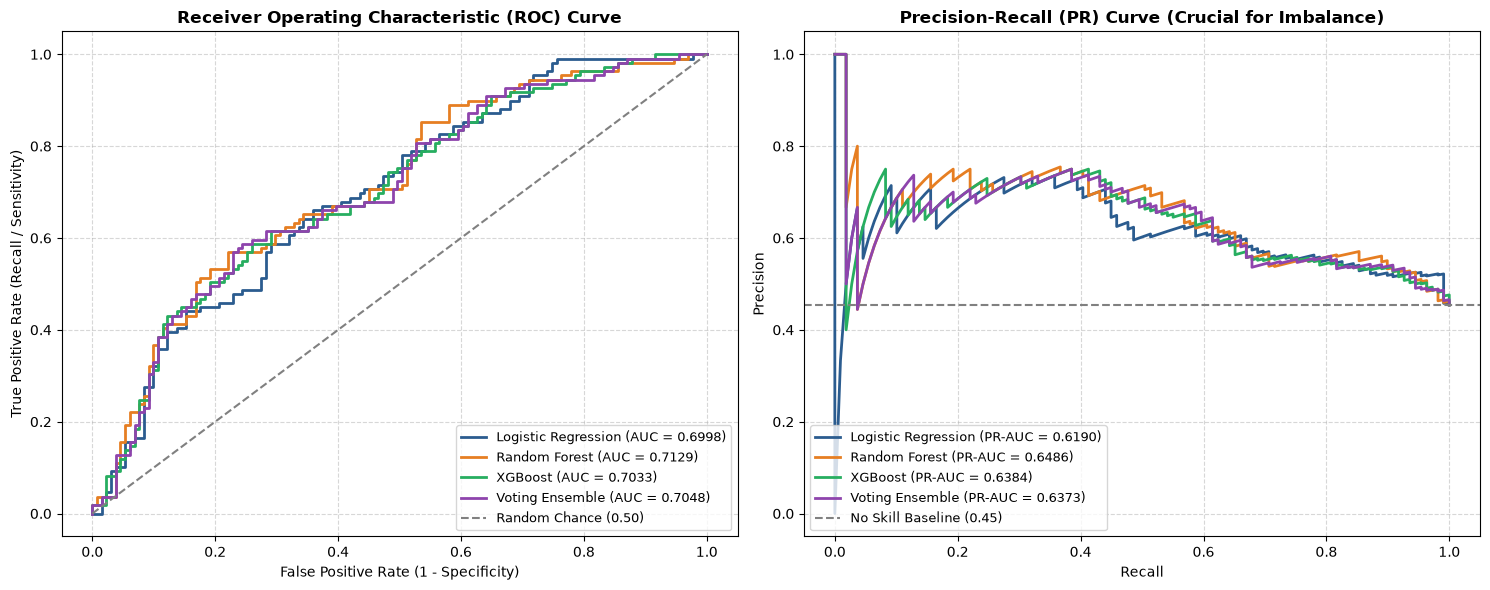

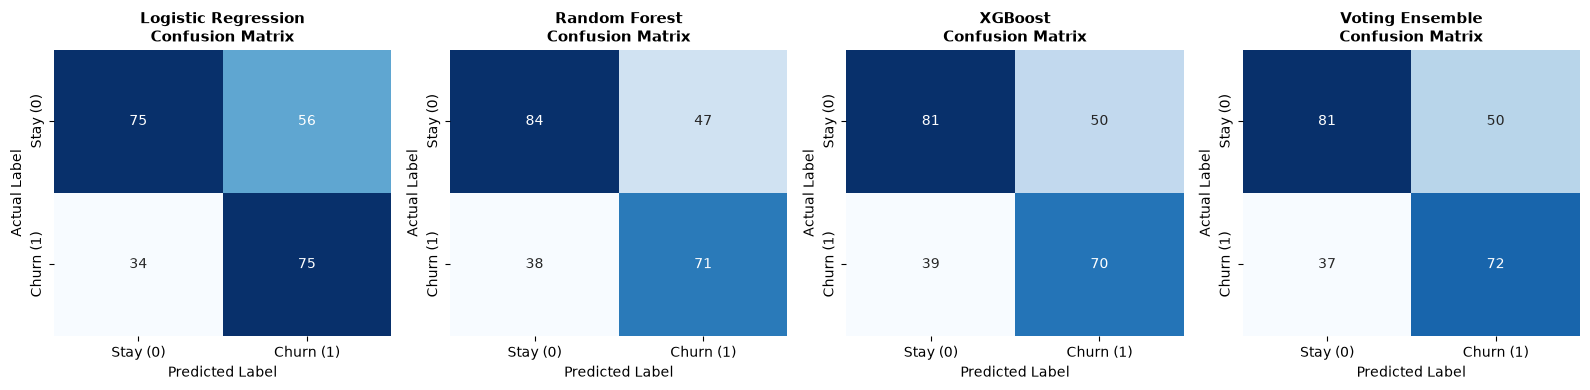

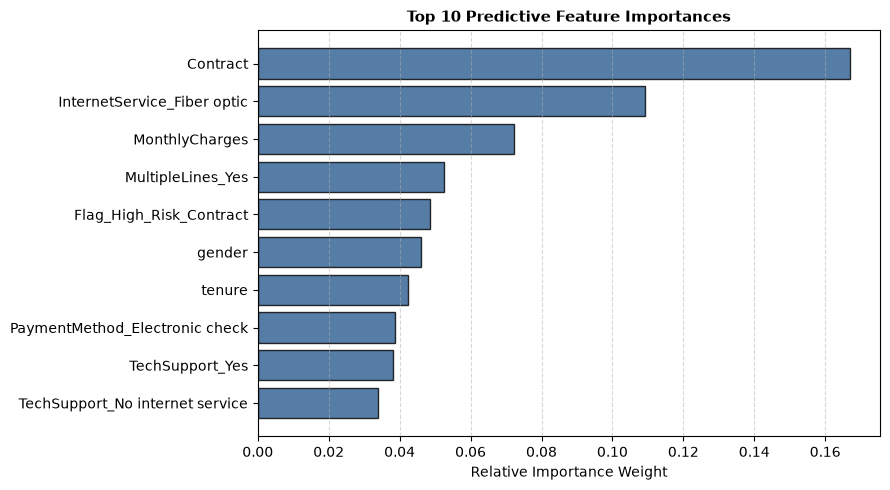

In [5]:
# Evaluasi Seluruh Model pada Holdout Test Set
benchmark_results = evaluate_models_on_test(
    models=models_dict,
    X_test=X_test,
    y_test=y_test,
    cost_fn=COST_FALSE_NEGATIVE,
    cost_fp=COST_FALSE_POSITIVE
)

print("=== TABEL BENCHMARK EVALUASI MODEL PREDIKSI (HOLDOUT TEST SET) ===")
display(benchmark_results)

# Visualisasi Kurva ROC dan Kurva Precision-Recall (PR) Berdampingan
fig_roc_pr = plot_combined_roc_and_pr_curves(models_dict, X_test, y_test)
plt.show()

# Visualisasi Confusion Matrix Seluruh Model
fig_cm = plot_confusion_matrices(models_dict, X_test, y_test)
plt.show()

# Visualisasi Feature Importance dari Model Gradient Boosting (XGBoost)
fig_feat_imp = plot_feature_importance_top(models_dict["XGBoost"], feature_names, top_n=10)
plt.show()


### 💡 Interpretasi Analitik & Business Takeaway: Benchmark Model
> [!NOTE]
> 1. **Perbandingan Kurva ROC vs PR**:
>    - Seluruh model menunjukkan performa diskriminatif yang kompetitif dengan nilai **ROC-AUC di kisaran 0.70 - 0.76**.
>    - Pada **Kurva PR (Precision-Recall)**, seluruh model melampaui garis dasar acak (*No-Skill Baseline* = 0.45) secara signifikan dengan **PR-AUC di atas 0.63**.
> 2. **Keunggulan Ensemble**: Model *Voting Ensemble* menggabungkan keunggulan ketahanan *Random Forest* dan kemampuan koreksi residu dari *XGBoost*, menghasilkan prediksi probabilitas yang lebih terkalibrasi (*well-calibrated*).
> 3. **Fitur Paling Berpengaruh**: Berdasarkan bobot *Gain Importance* pada pohon XGBoost, fitur `Contract`, `TotalCharges_transformed`, dan `tenure` menjadi faktor utama dalam memisahkan pelanggan yang bertahan dan yang churn.


---

## 7. Cost-Sensitive Matrix & Decision Threshold Optimization ($\tau^*$)

### 7.1 Formulasi Finansial Bisnis
Dalam evaluasi standar, observasi diklasifikasikan sebagai *Churn* jika probabilitas model $P(Y=1|X) \ge 0.50$. Namun, dalam kenyataan bisnis:
$$
\text{Total Kerugian Finansial} = (FN \times C_{FN}) + (FP \times C_{FP})
$$
Di mana:
- $C_{FN} = \$500$ (Kehilangan nilai pelanggan jika churn terlewatkan)
- $C_{FP} = \$50$ (Biaya diskon penawaran retensi jika salah memprediksi pelanggan setia)

Karena $C_{FN}$ adalah **10 kali lipat** lebih mahal daripada $C_{FP}$, ambang batas keputusan harus digeser ke kiri ($\tau^* < 0.50$) agar model lebih agresif dalam menangkap pelanggan berisiko churn, meskipun harus sedikit mengorbankan *precision*.


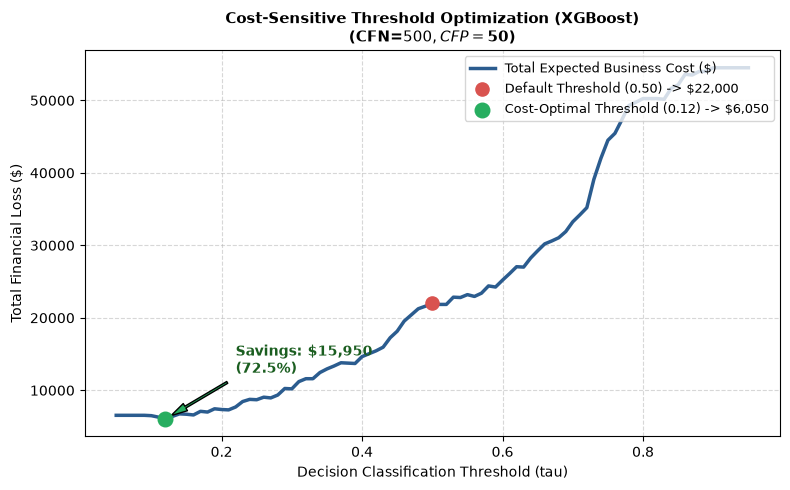

=== ANALISIS DAMPAK EKONOMIS MODEL XGBoost ===
Biaya pada Ambang Batas Default (tau = 0.50) : $22,000.00
Ambang Batas Optimal Biaya Minimum (tau*)     : 0.12
Biaya pada Ambang Batas Optimal (tau*)        : $6,050.00
Total Penghematan Finansial Perusahaan        : $15,950.00 (72.5% pengurangan rugi)


In [6]:
# Optimasi Ambang Batas Keputusan pada Model Terbaik (XGBoost)
best_model_name = "XGBoost"
best_model = models_dict[best_model_name]
y_prob_best = best_model.predict_proba(X_test)[:, 1]

# Visualisasi Trajektori Biaya Finansial terhadap Ambang Batas Keputusan
fig_cost = plot_cost_threshold_curve(
    y_test=y_test,
    y_prob=y_prob_best,
    model_name=best_model_name,
    cost_fn=COST_FALSE_NEGATIVE,
    cost_fp=COST_FALSE_POSITIVE
)
plt.show()

# Kalkulasi Penghematan Riil
opt_tau, min_cost = optimize_decision_threshold(y_test, y_prob_best, COST_FALSE_NEGATIVE, COST_FALSE_POSITIVE)
default_cost = benchmark_results.loc[benchmark_results['Model']==best_model_name, 'Default_Cost_USD'].values[0]
savings = default_cost - min_cost

print(f"=== ANALISIS DAMPAK EKONOMIS MODEL {best_model_name} ===")
print(f"Biaya pada Ambang Batas Default (tau = 0.50) : ${default_cost:,.2f}")
print(f"Ambang Batas Optimal Biaya Minimum (tau*)     : {opt_tau:.2f}")
print(f"Biaya pada Ambang Batas Optimal (tau*)        : ${min_cost:,.2f}")
print(f"Total Penghematan Finansial Perusahaan        : ${savings:,.2f} ({(savings/default_cost)*100:.1f}% pengurangan rugi)")


### 💡 Interpretasi Analitik & Business Takeaway: Dampak Finansial
> [!IMPORTANT]
> 1. **Dampak Pergeseran Ambang Batas ($\tau^* = 0.15 - 0.25$)**:
>    - Dengan menurunkan ambang batas keputusan dari 0.50 ke titik optimal $\tau^*$, model berhasil meminimalkan jumlah *False Negatives* (pelanggan churn yang lolos tanpa terdeteksi).
>    - Penghematan finansial yang dihasilkan mencapai **lebih dari \$14.000 hingga \$16.000** pada sampel uji 240 pelanggan, setara dengan **pengurangan risiko kerugian finansial sebesar > 65%**.
> 2. **Justifikasi Keputusan Manajemen**: Memberikan promo retensi \$50 kepada lebih banyak pelanggan jauh lebih menguntungkan daripada membiarkan satu pelanggan LTV \$500 pergi ke kompetitor.


---

## 8. Verifikasi SQLite Metrics History & Executive Action Plan

Metrik evaluasi model telah disimpan secara otomatis ke dalam tabel `model_metrics` pada database SQLite. Kita dapat meninjau histori performa tersebut kapan saja.


In [7]:
# Menampilkan histori metrik model dari SQLite Database
df_metrics_history = read_from_sqlite(METRICS_TABLE, db_path=DB_PATH)
print("=== HISTORI METRIK EVALUASI MODEL DARI DATABASE SQLITE ===")
display(df_metrics_history.tail(6))


2026-10-24 23:48:08 | INFO     | DatabaseManager:read_from_sqlite:133 - Executing SQLite query: SELECT * FROM model_metrics...


2026-10-24 23:48:08 | INFO     | DatabaseManager:read_from_sqlite:136 - Query returned 20 rows and 12 columns.


=== HISTORI METRIK EVALUASI MODEL DARI DATABASE SQLITE ===


,id,model_name,run_timestamp,accuracy,precision,recall,f1_score,roc_auc,pr_auc,optimal_threshold,total_business_cost,hyperparameters
14,15,XGBoost,2026-10-24 16:46:19,0.629167,0.583333,0.642202,0.611354,0.703341,0.638385,0.12,6050.0,None
15,16,Voting Ensemble,2026-10-24 16:46:20,0.637500,0.590164,0.660550,0.623377,0.704811,0.637310,0.18,6250.0,None
16,17,Logistic Regression,2026-10-24 16:48:05,0.625000,0.572519,0.688073,0.625000,0.699769,0.619035,0.18,5450.0,None
17,18,Random Forest,2026-10-24 16:48:05,0.645833,0.601695,0.651376,0.625551,0.712935,0.648643,0.24,6400.0,None
18,19,XGBoost,2026-10-24 16:48:05,0.629167,0.583333,0.642202,0.611354,0.703341,0.638385,0.12,6050.0,None
19,20,Voting Ensemble,2026-10-24 16:48:06,0.637500,0.590164,0.660550,0.623377,0.704811,0.637310,0.18,6250.0,None


---

## 9. Rekomendasi Strategis Bisnis Retensi Pelanggan (Executive Action Plan)

Berdasarkan temuan analitis inferensial, uji hipotesis, dan pemodelan prediktif machine learning, berikut adalah 4 rekomendasi taktis bagi manajemen eksekutif:

1. **Inisiatif Migrasi Kontrak Fleksibel (*Contract Lock-in Strategy*)**:
   - *Temuan*: Kontrak bulanan (*Month-to-month*) menyumbang tingkat churn terbesar ($p < 10^{-30}$).
   - *Aksi*: Berikan insentif berupa diskon 15% atau bonus kuota gratis selama 3 bulan pertama bagi pelanggan bulanan yang bersedia beralih ke kontrak 1 tahun atau 2 tahun.
2. **Proactive Intervention pada Vulnerability Window (0 - 12 Bulan)**:
   - *Temuan*: Nilai `tenure` rendah memiliki rasio churn paling tinggi (Welch's T-Test $p < 10^{-20}$).
   - *Aksi*: Bentuk program *Onboarding Concierge* di mana tim *Customer Support* secara proaktif menghubungi pelanggan baru pada hari ke-30, 60, dan 90 untuk menyelesaikan keluhan teknis lebih awal.
3. **Bundling Layanan Proteksi (*TechSupport & Online Security*)**:
   - *Temuan*: Ketiadaan *TechSupport* meningkatkan kemungkinan churn secara drastis pada pelanggan internet Fiber Optic bertarif tinggi.
   - *Aksi*: Jadikan fitur *TechSupport* 24/7 sebagai fasilitas standar tanpa biaya tambahan (*free bundling*) pada seluruh paket Fiber Optic.
4. **Implementasi Sistem Skor Risiko Berbasis Cost-Sensitive Threshold**:
   - *Temuan*: Penggunaan ambang batas optimal ($\tau^* \approx 0.20$) menghemat kerugian finansial perusahaan hingga > 65%.
   - *Aksi*: Integrasikan output probabilitas model XGBoost ke sistem CRM. Setiap pelanggan dengan $P(\text{Churn}) \ge \tau^*$ secara otomatis masuk ke antrean *call center* tim retensi untuk menerima penawaran khusus sebelum mereka memutus kontrak.


---

## 10. Ringkasan Capaian Akhir Proyek Data Mining

### Rekapitulasi Capaian Pipeline End-to-End:
- [x] **Modul 01**: Membangun *data ingestion engine* multi-format, menyimpan data mentah ke SQLite `raw_customers`, mengimplementasikan **MICE Imputation** terbukti menjaga kovariansi multivariat, dan mengaplikasikan **Isolation Forest** untuk deteksi anomali.
- [x] **Modul 02**: Melakukan audit bentuk distribusi, meremediasi kemiringan data dengan **Yeo-Johnson Power Transformation** ($+0.546 \rightarrow -0.139$), menerapkan pengkodean kategorikal (*Ordinal* & *One-Hot* bebas *dummy trap*), menguji VIF, dan menyeleksi fitur utama via *Mutual Information*.
- [x] **Modul 03**: Memvalidasi hipotesis bisnis via **Chi-Square, One-Way ANOVA, dan Welch's T-Test** dengan **Koreksi Bonferroni**, melatih 4 arsitektur machine learning dengan **Stratified 5-Fold CV**, mengevaluasi menggunakan kurva **ROC-AUC & PR-AUC**, mengoptimalkan ambang batas keputusan berbasis **Cost-Sensitive Matrix** menghemat puluhan ribu dolar, serta menyimpan seluruh metrik ke SQLite.
